# Lusaka air quality, August 2022 to February 2026

Portfolio notebook by **Dennis Kabaso**, a computer science student in Lusaka who is learning data analysis.

The questions below are about daily air quality for Lusaka. The answers use pandas, and the charts use matplotlib and seaborn. The style is a straight question, a short piece of code, and a chart.

**These values are modelled estimates from the Open-Meteo Air Quality API (CAMS global). They are not measurements from ground monitors in Lusaka, and they are not an official health or regulatory report.**

Data: Kulkarni Nitiraj and Tawade Jagadish, *Air Quality Dataset for Lusaka (2022-08-01 to 2026-02-18)*, Zenodo, [10.5281/zenodo.18680531](https://doi.org/10.5281/zenodo.18680531). The dataset is CC0. The authors are still credited here.

### Questions

1. What is the average PM2.5 by month and by season?
2. Which months have the worst air?
3. How many days reach US AQI "Unhealthy" (above 150) or "Unhealthy for sensitive groups" (101-150), by year?
4. Do dust and PM10 rise in the dry season?
5. How strongly are the pollutants correlated?
6. Is the air getting better or worse from 2023 to 2025? (Full years only.)

Zambian seasons used throughout:

- **Cool dry:** May-August
- **Hot dry:** September-November
- **Rainy:** December-April (this season crosses the new year)

## Setup

Load the libraries, find the project folder, and set a few shared labels. The season colours stay the same in every chart.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display


def find_project_root() -> Path:
    """Find the folder that contains data/raw, from the repo root or from notebooks/."""
    start = Path.cwd().resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw" / "air_quality_historical.csv").exists():
            return folder
    raise FileNotFoundError(
        "Could not find data/raw/air_quality_historical.csv. "
        "Open this notebook from the project folder."
    )


ROOT = find_project_root()
DATA = ROOT / "data" / "raw"
IMAGES = ROOT / "images"
IMAGES.mkdir(parents=True, exist_ok=True)

# Zambia's three seasons, and the months that belong to each one.
SEASON_ORDER = ["Cool dry", "Hot dry", "Rainy"]
SEASON_MONTHS = {
    "Cool dry": "May-Aug",
    "Hot dry": "Sep-Nov",
    "Rainy": "Dec-Apr",
}
SEASON_COLORS = {
    "Cool dry": "#4C78A8",
    "Hot dry": "#F58518",
    "Rainy": "#54A24B",
}
MONTH_LABELS = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]
MONTH_FULL = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December",
]
MONTH_NAME = dict(enumerate(MONTH_LABELS, start=1))
MONTH_NAME_FULL = dict(enumerate(MONTH_FULL, start=1))
# Dry season in this notebook = cool dry + hot dry (May through November).
DRY_MONTHS = {5, 6, 7, 8, 9, 10, 11}
SOURCE_NOTE = "Modelled Open-Meteo/CAMS estimates, not ground-monitor readings."

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})


def zambian_season(month: int) -> str:
    """Map a month number to the Zambian season used in this project."""
    if month in (5, 6, 7, 8):
        return "Cool dry"
    if month in (9, 10, 11):
        return "Hot dry"
    return "Rainy"


def style_ax(ax) -> None:
    """Keep horizontal gridlines only, and draw them behind the marks."""
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle=":", alpha=0.7)
    ax.grid(axis="x", visible=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def season_handles():
    """Legend entries that pair each season colour with its months."""
    return [
        Patch(facecolor=SEASON_COLORS[name], label=f"{name} ({SEASON_MONTHS[name]})")
        for name in SEASON_ORDER
    ]


def label_bars(ax, fmt: str = "{:.1f}") -> None:
    """Write each bar height just above the bar."""
    for bar in ax.patches:
        height = bar.get_height()
        if height is None or pd.isna(height):
            continue
        ax.annotate(
            fmt.format(height),
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            color="#333333",
        )


def add_source_note(fig, bottom: float = 0.14) -> None:
    """Leave room under the axes for a one-line source reminder."""
    fig.tight_layout()
    fig.subplots_adjust(bottom=bottom)
    fig.text(0.01, 0.01, SOURCE_NOTE, ha="left", va="bottom", fontsize=8, color="#555555")


def legend_on_the_right(fig, handles, bottom: float = 0.16) -> None:
    """Park the legend beside the axes so it does not cover the bars."""
    fig.tight_layout()
    fig.subplots_adjust(right=0.68, bottom=bottom)
    fig.legend(
        handles=handles,
        loc="center left",
        bbox_to_anchor=(0.70, 0.55),
        frameon=False,
    )
    fig.text(0.01, 0.01, SOURCE_NOTE, ha="left", va="bottom", fontsize=8, color="#555555")


def save_chart(fig, filename: str) -> None:
    """Save the figure under images/ and show it in the notebook."""
    fig.savefig(IMAGES / filename, dpi=160, bbox_inches="tight", facecolor="white", pad_inches=0.25)
    display(fig)
    plt.close(fig)


print(f"Reading data from {DATA.relative_to(ROOT)}")
print(f"Saving charts to {IMAGES.relative_to(ROOT)}")

Reading data from data/raw
Saving charts to images


## Load the data

Three files live in `data/raw/`:

- `air_quality_historical.csv` is one row per day
- `city_info.csv` is the Lusaka location and population
- `data_dictionary.csv` defines the columns and units

PM concentrations are in micrograms per cubic metre (µg/m³). `us_aqi` is the US AQI already stored in the file. This notebook does not recalculate the index.

In [2]:
air = pd.read_csv(DATA / "air_quality_historical.csv", parse_dates=["date"])
city = pd.read_csv(DATA / "city_info.csv")
dictionary = pd.read_csv(DATA / "data_dictionary.csv")
air = air.sort_values("date").reset_index(drop=True)

place = city.iloc[0]
print(
    f"{place.city_name} ({place.country_code}), "
    f"latitude {place.latitude:.5f}, longitude {place.longitude:.5f}, "
    f"GeoNames population {int(place.population):,}."
)
print(
    f"{len(air):,} daily rows, "
    f"{air['date'].min():%d %b %Y} to {air['date'].max():%d %b %Y}."
)

print("Columns in the daily file:")
daily_dictionary = dictionary.loc[
    dictionary["file"] == "air_quality_historical.csv",
    ["column", "unit", "description"],
]
display(daily_dictionary.reset_index(drop=True))

# european_aqi and uv_index are in the file. The questions below do not use them.
preview_cols = [
    "date", "pm2_5", "pm10", "ozone", "nitrogen_dioxide",
    "sulphur_dioxide", "carbon_monoxide", "dust", "us_aqi",
]
display(air[preview_cols].head(8))

blank_days = air.loc[air["pm2_5"].isna(), "date"]
aqi_gap = air.loc[air["pm2_5"].notna() & air["us_aqi"].isna(), "date"]
print(
    "Days with no pollutant values: "
    f"{len(blank_days)} ({', '.join(blank_days.dt.strftime('%Y-%m-%d'))})."
)
print(
    "Days with pollutants but no US AQI: "
    f"{len(aqi_gap)} ({', '.join(aqi_gap.dt.strftime('%Y-%m-%d'))})."
)
print("Those rows stay in the file. Each question drops missing values only for the columns it uses.")

Lusaka (ZM), latitude -15.40669, longitude 28.28713, GeoNames population 2,212,301.
1,298 daily rows, 01 Aug 2022 to 18 Feb 2026.
Columns in the daily file:


,column,unit,description
0,date,YYYY-MM-DD,Time index.
1,pm2_5,µg/m³,PM2.5 concentration.
2,pm10,µg/m³,PM10 concentration.
3,ozone,µg/m³,Ozone concentration.
4,nitrogen_dioxide,µg/m³,NO2 concentration.
5,sulphur_dioxide,µg/m³,SO2 concentration.
6,carbon_monoxide,µg/m³,CO concentration.
7,us_aqi,index,US AQI index.
8,european_aqi,index,European AQI index.
9,uv_index,index,UV index.


,date,pm2_5,pm10,ozone,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,dust,us_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,6.936364,10.068182,62.500000,1.454545,0.881818,296.045455,0.0,NaN
4,2022-08-05,6.679167,9.758333,76.541667,2.187500,0.891667,455.666667,0.0,35.318182
5,2022-08-06,13.850000,20.087500,77.166667,1.983333,1.329167,332.625000,0.0,38.041667
6,2022-08-07,14.754167,21.445833,81.625000,2.020833,1.500000,326.791667,0.0,57.333333
7,2022-08-08,13.395833,19.354167,82.208333,1.945833,1.466667,293.458333,0.0,54.083333


Days with no pollutant values: 3 (2022-08-01, 2022-08-02, 2022-08-03).
Days with pollutants but no US AQI: 1 (2022-08-04).
Those rows stay in the file. Each question drops missing values only for the columns it uses.


## Add the calendar columns

Month, year, and season are derived from the date. The rainy season crosses January, so a day in December and a day the following January are both rainy.

In [3]:
air["year"] = air["date"].dt.year
air["month"] = air["date"].dt.month
air["month_label"] = air["month"].map(MONTH_NAME)
air["season"] = air["month"].map(zambian_season)
air["year_month"] = air["date"].dt.to_period("M").astype(str)
air["is_dry_season"] = air["month"].isin(DRY_MONTHS)

# PM questions use days that have a PM2.5 value. AQI questions use days that have a US AQI.
daily = air.dropna(subset=["pm2_5"]).copy()
with_aqi = air.dropna(subset=["us_aqi"]).copy()

print(f"Days used for PM2.5: {len(daily):,}")
print(f"Days used for US AQI: {len(with_aqi):,}")
print("Coverage of the PM2.5 series:")
coverage = daily.groupby("year")["date"].agg(["min", "max", "count"])
for year, row in coverage.iterrows():
    print(f"  {int(year)}: {int(row['count'])} days, {row['min']:%d %b} to {row['max']:%d %b}")

Days used for PM2.5: 1,295
Days used for US AQI: 1,294
Coverage of the PM2.5 series:
  2022: 150 days, 04 Aug to 31 Dec
  2023: 365 days, 01 Jan to 31 Dec
  2024: 366 days, 01 Jan to 31 Dec
  2025: 365 days, 01 Jan to 31 Dec
  2026: 49 days, 01 Jan to 18 Feb


## Question 1: What is the average PM2.5 by month and by season?

PM2.5 is fine particulate matter. The averages below use every day in the file that has a PM2.5 value. The day count is in the table, because 2022 and 2026 are partial years, so the months do not all rest on the same set of years.

Average PM2.5 by month. Units are µg/m³.


,Month,Season,Days,Average PM2.5,Median PM2.5
0,Jan,Rainy,124,11.27,10.60
1,Feb,Rainy,103,12.95,12.23
2,Mar,Rainy,93,8.62,6.92
3,Apr,Rainy,90,7.38,6.21
4,May,Cool dry,93,6.73,5.14
5,Jun,Cool dry,90,9.31,7.05
6,Jul,Cool dry,93,9.71,6.43
7,Aug,Cool dry,121,12.05,10.54
8,Sep,Hot dry,120,15.11,15.16
9,Oct,Hot dry,124,15.24,14.03


Average PM2.5 by season.


,Season,Months,Days,Average PM2.5,Median PM2.5
0,Cool dry,May-Aug,397,9.63,7.57
1,Hot dry,Sep-Nov,364,13.25,12.17
2,Rainy,Dec-Apr,534,9.93,8.69


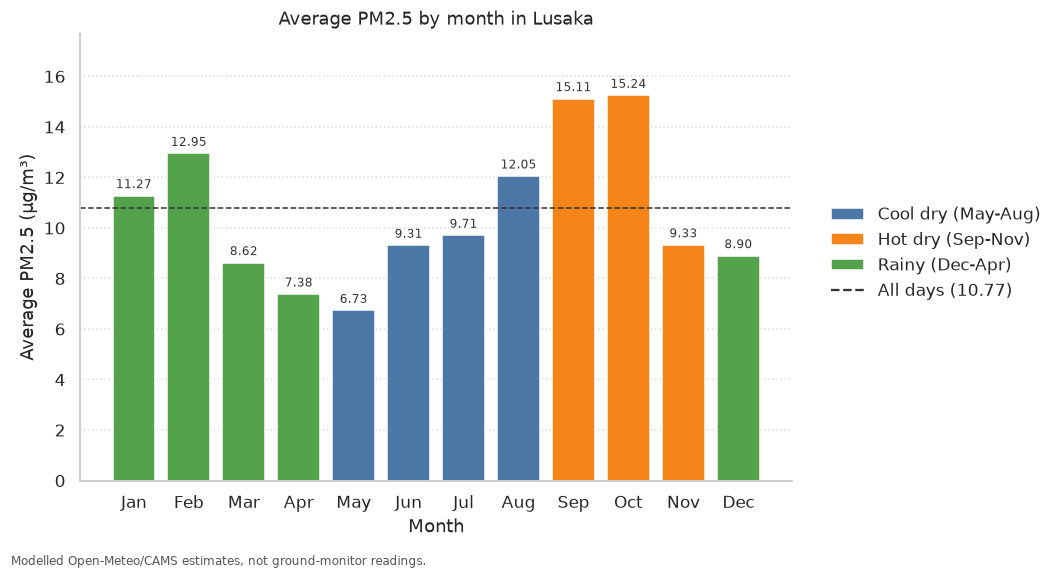

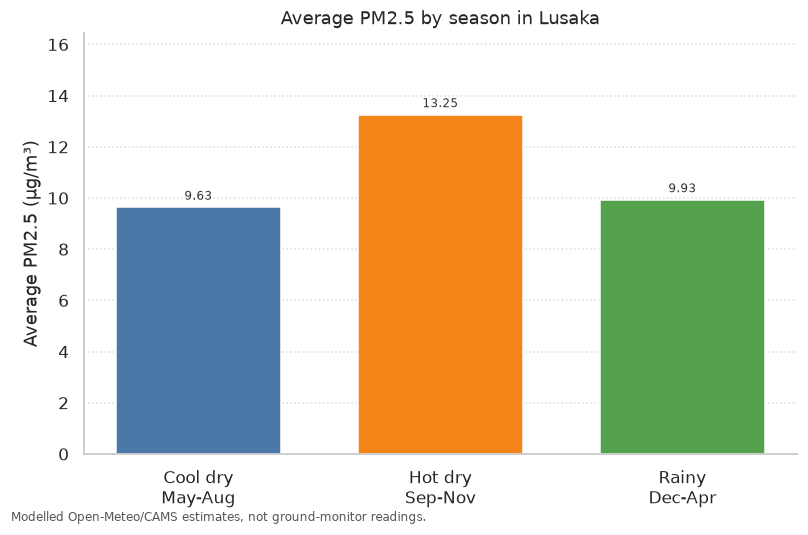

Finding: Across every day with PM2.5, October has the highest monthly average (15.24 µg/m³) and May the lowest (6.73 µg/m³). Season averages are Cool dry 9.63, Hot dry 13.25, Rainy 9.93 µg/m³.
The month averages above use every PM2.5 day in the file. 2022 and 2026 are partial, so the months do not all contain the same years. Question 2 repeats the ranking on the three complete years.


In [4]:
month_summary = (
    daily.groupby("month", as_index=False)
    .agg(
        days=("pm2_5", "count"),
        average_pm25=("pm2_5", "mean"),
        median_pm25=("pm2_5", "median"),
    )
    .sort_values("month")
)
month_summary["month_label"] = month_summary["month"].map(MONTH_NAME)
month_summary["season"] = month_summary["month"].map(zambian_season)

season_summary = (
    daily.groupby("season", as_index=False)
    .agg(
        days=("pm2_5", "count"),
        average_pm25=("pm2_5", "mean"),
        median_pm25=("pm2_5", "median"),
    )
)
season_summary["season"] = pd.Categorical(
    season_summary["season"], categories=SEASON_ORDER, ordered=True
)
season_summary = season_summary.sort_values("season")

print("Average PM2.5 by month. Units are µg/m³.")
month_view = month_summary[["month_label", "season", "days", "average_pm25", "median_pm25"]].copy()
month_view["average_pm25"] = month_view["average_pm25"].round(2)
month_view["median_pm25"] = month_view["median_pm25"].round(2)
month_view = month_view.rename(columns={
    "month_label": "Month",
    "season": "Season",
    "days": "Days",
    "average_pm25": "Average PM2.5",
    "median_pm25": "Median PM2.5",
})
display(month_view)

print("Average PM2.5 by season.")
season_view = season_summary.copy()
season_view["months"] = season_view["season"].astype(str).map(SEASON_MONTHS)
season_view["average_pm25"] = season_view["average_pm25"].round(2)
season_view["median_pm25"] = season_view["median_pm25"].round(2)
season_view = season_view.rename(columns={
    "season": "Season",
    "months": "Months",
    "days": "Days",
    "average_pm25": "Average PM2.5",
    "median_pm25": "Median PM2.5",
})
display(season_view[["Season", "Months", "Days", "Average PM2.5", "Median PM2.5"]])

fig, ax = plt.subplots(figsize=(10.6, 5.3))
ax.bar(
    month_summary["month_label"],
    month_summary["average_pm25"],
    color=[SEASON_COLORS[season] for season in month_summary["season"]],
    width=0.78,
)
overall_pm25 = daily["pm2_5"].mean()
ax.axhline(overall_pm25, color="#333333", linestyle="--", linewidth=1)
ax.set_ylim(0, month_summary["average_pm25"].max() * 1.16)
label_bars(ax, "{:.2f}")
ax.set_title("Average PM2.5 by month in Lusaka")
ax.set_ylabel("Average PM2.5 (µg/m³)")
ax.set_xlabel("Month")
handles = season_handles() + [
    Line2D([0], [0], color="#333333", linestyle="--", label=f"All days ({overall_pm25:.2f})")
]
style_ax(ax)
legend_on_the_right(fig, handles)
save_chart(fig, "pm25_by_month.png")

fig, ax = plt.subplots(figsize=(7.4, 4.9))
positions = list(range(len(season_summary)))
ax.bar(
    positions,
    season_summary["average_pm25"],
    color=[SEASON_COLORS[season] for season in season_summary["season"]],
    width=0.68,
)
ax.set_ylim(0, season_summary["average_pm25"].max() * 1.24)
label_bars(ax, "{:.2f}")
ax.set_xticks(positions)
ax.set_xticklabels(
    [f"{season}\n{SEASON_MONTHS[str(season)]}" for season in season_summary["season"]]
)
ax.set_title("Average PM2.5 by season in Lusaka")
ax.set_ylabel("Average PM2.5 (µg/m³)")
style_ax(ax)
add_source_note(fig)
save_chart(fig, "pm25_by_season.png")

highest = month_summary.loc[month_summary["average_pm25"].idxmax()]
lowest = month_summary.loc[month_summary["average_pm25"].idxmin()]
season_bits = ", ".join(
    f"{row.season} {row.average_pm25:.2f}"
    for row in season_summary.itertuples(index=False)
)
print(
    f"Finding: Across every day with PM2.5, {MONTH_NAME_FULL[int(highest.month)]} has the highest monthly average "
    f"({highest.average_pm25:.2f} µg/m³) and {MONTH_NAME_FULL[int(lowest.month)]} the lowest "
    f"({lowest.average_pm25:.2f} µg/m³). "
    f"Season averages are {season_bits} µg/m³."
)
print(
    "The month averages above use every PM2.5 day in the file. "
    "2022 and 2026 are partial, so the months do not all contain the same years. "
    "Question 2 repeats the ranking on the three complete years."
)

## Question 2: Which months have the worst air?

"Worst" here means the highest average PM2.5. Average US AQI is shown beside it as a check. The line chart is every month in the file. The ranking of single months skips any month with fewer than 28 days, so a short final month cannot win on a handful of days.

The bar chart then uses only 2023, 2024, and 2025. Those three years are complete, so each calendar month is made of the same three years. That is the fairer picture of a typical month. 2022 only covers August-December, and those months include the dirtiest stretch in the file, which pulls the all-data October average up.

Left out of the ranking because they have fewer than 28 days: 2026-02 (18 days).
Five highest months with at least 28 PM2.5 days.


,Month,Days,Average PM2.5,Average US AQI
2,2022-10,31,23.46,77.32
6,2023-02,28,20.63,67.59
37,2025-09,30,17.57,71.83
0,2022-08,28,17.21,60.98
23,2024-07,31,16.92,58.76


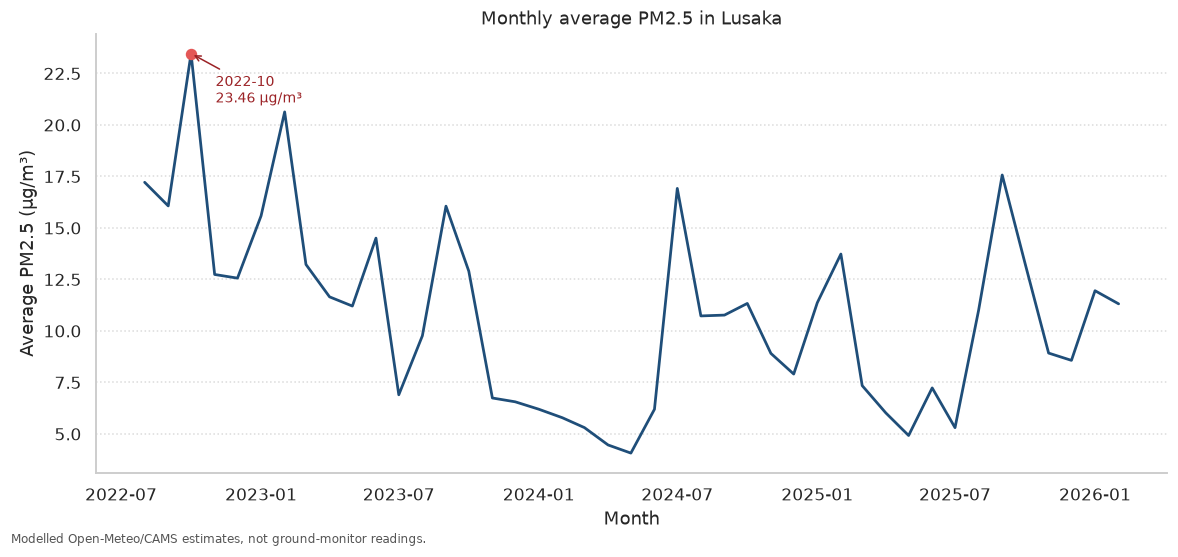

Average by calendar month for 2023, 2024, and 2025 only, sorted from worst to best.


,Month,Season,Days,Average PM2.5,Average US AQI
8,Sep,Hot dry,90,14.80,61.06
1,Feb,Rainy,85,13.29,47.50
9,Oct,Hot dry,93,12.51,52.94
0,Jan,Rainy,93,11.05,42.08
7,Aug,Cool dry,93,10.50,46.87
6,Jul,Cool dry,93,9.71,41.78
5,Jun,Cool dry,90,9.31,41.12
2,Mar,Rainy,93,8.62,34.96
10,Nov,Hot dry,90,8.19,37.09
11,Dec,Rainy,93,7.68,35.37


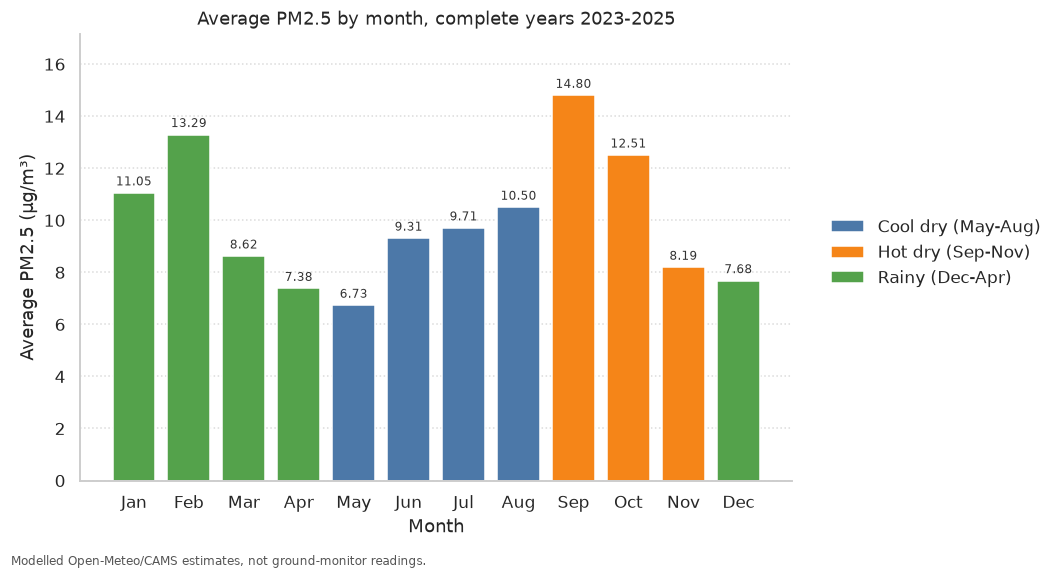

Finding: The worst month in the file, among months with at least 28 days, is 2022-10 (average PM2.5 23.46 µg/m³, average US AQI 77.32). On the complete years 2023-2025, the highest months are September 14.80, February 13.29, October 12.51 µg/m³.


In [5]:
timeline = (
    daily.groupby("year_month", as_index=False)
    .agg(
        days=("pm2_5", "count"),
        average_pm25=("pm2_5", "mean"),
        average_aqi=("us_aqi", "mean"),
    )
)
timeline["month_start"] = pd.to_datetime(timeline["year_month"])

# February 2026 has 18 days. Leave short months out of the "worst month" ranking.
complete_months = timeline.loc[timeline["days"] >= 28].copy()
short_months = timeline.loc[timeline["days"] < 28]
if short_months.empty:
    print("Every month in the file has at least 28 PM2.5 days.")
else:
    short_bits = ", ".join(
        f"{row.year_month} ({int(row.days)} days)"
        for row in short_months.itertuples(index=False)
    )
    print(f"Left out of the ranking because they have fewer than 28 days: {short_bits}.")

worst_months = complete_months.sort_values("average_pm25", ascending=False).head(5)
print("Five highest months with at least 28 PM2.5 days.")
worst_view = worst_months[["year_month", "days", "average_pm25", "average_aqi"]].copy()
worst_view["average_pm25"] = worst_view["average_pm25"].round(2)
worst_view["average_aqi"] = worst_view["average_aqi"].round(2)
worst_view = worst_view.rename(columns={
    "year_month": "Month",
    "days": "Days",
    "average_pm25": "Average PM2.5",
    "average_aqi": "Average US AQI",
})
display(worst_view)

worst = complete_months.loc[complete_months["average_pm25"].idxmax()]
fig, ax = plt.subplots(figsize=(10.8, 5.1))
ax.plot(timeline["month_start"], timeline["average_pm25"], color="#1F4E79", linewidth=1.8)
ax.scatter([worst["month_start"]], [worst["average_pm25"]], color="#E45756", s=42, zorder=3)
ax.annotate(
    f"{worst['year_month']}\n{worst['average_pm25']:.2f} µg/m³",
    xy=(worst["month_start"], worst["average_pm25"]),
    xytext=(16, -32),
    textcoords="offset points",
    fontsize=9,
    color="#9B2226",
    arrowprops={"arrowstyle": "->", "color": "#9B2226"},
)
ax.set_title("Monthly average PM2.5 in Lusaka")
ax.set_ylabel("Average PM2.5 (µg/m³)")
ax.set_xlabel("Month")
style_ax(ax)
add_source_note(fig)
save_chart(fig, "pm25_over_time.png")

# Each calendar month below contains the same three complete years.
full_years = [2023, 2024, 2025]
full = daily.loc[daily["year"].isin(full_years)].copy()
full_month = (
    full.groupby("month", as_index=False)
    .agg(
        days=("pm2_5", "count"),
        average_pm25=("pm2_5", "mean"),
        median_pm25=("pm2_5", "median"),
        average_aqi=("us_aqi", "mean"),
    )
    .sort_values("month")
)
full_month["month_label"] = full_month["month"].map(MONTH_NAME)
full_month["season"] = full_month["month"].map(zambian_season)

print("Average by calendar month for 2023, 2024, and 2025 only, sorted from worst to best.")
full_view = full_month.sort_values("average_pm25", ascending=False)[
    ["month_label", "season", "days", "average_pm25", "average_aqi"]
].copy()
full_view["average_pm25"] = full_view["average_pm25"].round(2)
full_view["average_aqi"] = full_view["average_aqi"].round(2)
full_view = full_view.rename(columns={
    "month_label": "Month",
    "season": "Season",
    "days": "Days",
    "average_pm25": "Average PM2.5",
    "average_aqi": "Average US AQI",
})
display(full_view)

fig, ax = plt.subplots(figsize=(10.6, 5.3))
ax.bar(
    full_month["month_label"],
    full_month["average_pm25"],
    color=[SEASON_COLORS[season] for season in full_month["season"]],
    width=0.78,
)
ax.set_ylim(0, full_month["average_pm25"].max() * 1.16)
label_bars(ax, "{:.2f}")
ax.set_title("Average PM2.5 by month, complete years 2023-2025")
ax.set_ylabel("Average PM2.5 (µg/m³)")
ax.set_xlabel("Month")
style_ax(ax)
legend_on_the_right(fig, season_handles())
save_chart(fig, "pm25_by_month_full_years.png")

top_full = full_month.sort_values("average_pm25", ascending=False).head(3)
top_bits = ", ".join(
    f"{MONTH_NAME_FULL[int(row.month)]} {row.average_pm25:.2f}"
    for row in top_full.itertuples(index=False)
)
print(
    f"Finding: The worst month in the file, among months with at least 28 days, is {worst['year_month']} "
    f"(average PM2.5 {worst['average_pm25']:.2f} µg/m³, average US AQI {worst['average_aqi']:.2f}). "
    f"On the complete years 2023-2025, the highest months are {top_bits} µg/m³."
)

## Question 3: How many days are Unhealthy, or Unhealthy for sensitive groups?

The file already has a daily US AQI. These counts use that column as published.

Bands used here, matching the question:

- **Unhealthy for sensitive groups:** 101 to 150, inclusive
- **Unhealthy or worse:** above 150 (Unhealthy, Very Unhealthy, and Hazardous)

A day above 100 and below 101 is listed separately. It is past the top of the Moderate band and it is not inside 101-150, so it is not counted in either total above.

2022 starts on 1 August and 2026 ends on 18 February. Compare those years with the day counts in the table, not as if they were full years.

Days in the two bands the question asks about.


,Year,Days with US AQI,Sensitive groups (101-150),Unhealthy or worse (above 150)
0,2022,149,2,0
1,2023,365,1,0
2,2024,366,0,0
3,2025,365,1,0
4,2026,49,0,0


All four bands, for context. Most days are Good or Moderate.


band,Year,Good (0-50),Moderate (above 50 and below 101),Sensitive groups (101-150),Unhealthy or worse (above 150)
0,2022,47,100,2,0
1,2023,207,157,1,0
2,2024,297,69,0,0
3,2025,267,97,1,0
4,2026,25,24,0,0


Days with US AQI from 101 to 150:


,Date,US AQI,PM2.5,PM10
0,2022-08-15,121.08,39.78,57.18
1,2022-10-04,110.00,32.81,47.90
2,2025-09-06,105.79,32.60,33.11
3,2023-02-14,102.25,33.95,48.70


Days above 100 and below 101 (not counted in the 101-150 band):


,Date,US AQI,PM2.5,PM10
0,2024-07-31,100.42,27.53,39.93
1,2022-08-14,100.17,43.65,62.81
2,2022-10-16,100.17,32.79,47.35


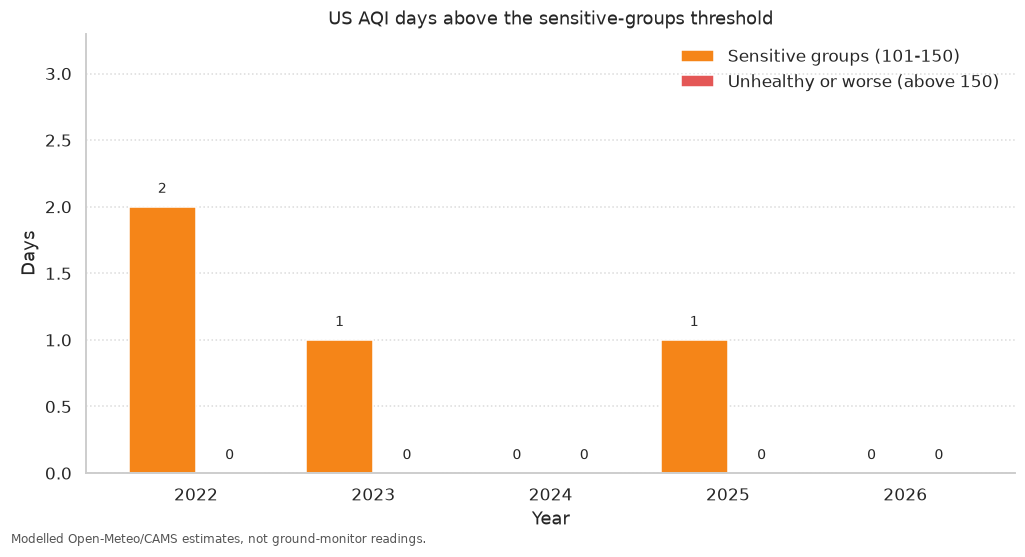

Finding: Days with US AQI above 150: 0. The highest US AQI in the file is 121.08 on 2022-08-15. Days from 101 to 150: 4 (2022: 2, 2023: 1, 2024: 0, 2025: 1, 2026: 0). Those days are 2022-08-15 (121.08), 2022-10-04 (110.00), 2025-09-06 (105.79), 2023-02-14 (102.25). Days above 100 and below 101: 3.


In [6]:
# Assign every AQI day to exactly one band.
bands = pd.Series("Moderate (above 50 and below 101)", index=with_aqi.index)
bands.loc[with_aqi["us_aqi"] <= 50] = "Good (0-50)"
bands.loc[(with_aqi["us_aqi"] >= 101) & (with_aqi["us_aqi"] <= 150)] = "Sensitive groups (101-150)"
bands.loc[with_aqi["us_aqi"] > 150] = "Unhealthy or worse (above 150)"
with_aqi = with_aqi.copy()
with_aqi["band"] = bands

band_order = [
    "Good (0-50)",
    "Moderate (above 50 and below 101)",
    "Sensitive groups (101-150)",
    "Unhealthy or worse (above 150)",
]
band_counts = (
    pd.crosstab(with_aqi["year"], with_aqi["band"])
    .reindex(columns=band_order, fill_value=0)
    .sort_index()
)
if int(band_counts.to_numpy().sum()) != len(with_aqi):
    raise ValueError("AQI bands do not cover every day that has a US AQI.")

sensitive = with_aqi[(with_aqi["us_aqi"] >= 101) & (with_aqi["us_aqi"] <= 150)].sort_values(
    "us_aqi", ascending=False
)
unhealthy = with_aqi[with_aqi["us_aqi"] > 150]
border = with_aqi[(with_aqi["us_aqi"] > 100) & (with_aqi["us_aqi"] < 101)].sort_values(
    "us_aqi", ascending=False
)

year_summary = pd.DataFrame({"Year": band_counts.index.astype(int)})
year_summary["Days with US AQI"] = band_counts.sum(axis=1).to_numpy()
year_summary["Sensitive groups (101-150)"] = band_counts["Sensitive groups (101-150)"].to_numpy()
year_summary["Unhealthy or worse (above 150)"] = band_counts["Unhealthy or worse (above 150)"].to_numpy()
print("Days in the two bands the question asks about.")
display(year_summary)

print("All four bands, for context. Most days are Good or Moderate.")
display(band_counts.rename_axis("Year").reset_index())

def show_aqi_days(frame, label):
    """Print a small date list for one AQI band."""
    print(label)
    if frame.empty:
        print("None.")
        return
    view = frame[["date", "us_aqi", "pm2_5", "pm10"]].copy()
    view["date"] = view["date"].dt.strftime("%Y-%m-%d")
    view["us_aqi"] = view["us_aqi"].round(2)
    view["pm2_5"] = view["pm2_5"].round(2)
    view["pm10"] = view["pm10"].round(2)
    display(view.rename(columns={
        "date": "Date",
        "us_aqi": "US AQI",
        "pm2_5": "PM2.5",
        "pm10": "PM10",
    }).reset_index(drop=True))


show_aqi_days(sensitive, "Days with US AQI from 101 to 150:")
show_aqi_days(border, "Days above 100 and below 101 (not counted in the 101-150 band):")

years = list(band_counts.index.astype(int))
usg_counts = band_counts["Sensitive groups (101-150)"].to_numpy()
bad_counts = band_counts["Unhealthy or worse (above 150)"].to_numpy()
positions = list(range(len(years)))
width = 0.38

fig, ax = plt.subplots(figsize=(9.4, 5.1))
ax.bar(
    [i - width / 2 for i in positions],
    usg_counts,
    width=width,
    color="#F58518",
    label="Sensitive groups (101-150)",
)
ax.bar(
    [i + width / 2 for i in positions],
    bad_counts,
    width=width,
    color="#E45756",
    label="Unhealthy or worse (above 150)",
)
for i, (left_count, right_count) in enumerate(zip(usg_counts, bad_counts)):
    ax.text(i - width / 2, left_count + 0.08, f"{int(left_count)}", ha="center", va="bottom", fontsize=9)
    ax.text(i + width / 2, right_count + 0.08, f"{int(right_count)}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(positions)
ax.set_xticklabels([str(year) for year in years])
ax.set_ylim(0, max(float(usg_counts.max()), float(bad_counts.max()), 1) + 1.3)
ax.set_ylabel("Days")
ax.set_xlabel("Year")
ax.set_title("US AQI days above the sensitive-groups threshold")
ax.legend(loc="upper right")
style_ax(ax)
add_source_note(fig)
save_chart(fig, "aqi_categories_by_year.png")

peak = with_aqi.loc[with_aqi["us_aqi"].idxmax()]
if sensitive.empty:
    sensitive_bits = "none"
else:
    sensitive_bits = ", ".join(
        f"{row.date:%Y-%m-%d} ({row.us_aqi:.2f})" for row in sensitive.itertuples(index=False)
    )
count_bits = ", ".join(
    f"{int(year)}: {int(count)}"
    for year, count in band_counts["Sensitive groups (101-150)"].items()
)
print(
    f"Finding: Days with US AQI above 150: {len(unhealthy)}. "
    f"The highest US AQI in the file is {peak.us_aqi:.2f} on {peak.date:%Y-%m-%d}. "
    f"Days from 101 to 150: {len(sensitive)} ({count_bits}). "
    f"Those days are {sensitive_bits}. "
    f"Days above 100 and below 101: {len(border)}."
)

## Question 4: Do dust and PM10 rise in the dry season?

The dry season here is May through November (cool dry plus hot dry). The rainy season is December through April.

PM10 includes coarser particles as well as PM2.5. Dust is its own column in the file. Both are modelled CAMS fields. Read the dust result with the day counts: the median is the more honest "typical day" when most days are zero.

PM10 and dust by season. Concentrations are µg/m³.


,Season,Months,Days,Average PM10,Median PM10,Average dust,Median dust,Days with dust > 0
0,Cool dry,May-Aug,397,13.24,10.06,0.018,0.0,27
1,Hot dry,Sep-Nov,364,17.82,15.86,0.017,0.0,22
2,Rainy,Dec-Apr,534,12.60,10.56,0.076,0.0,45


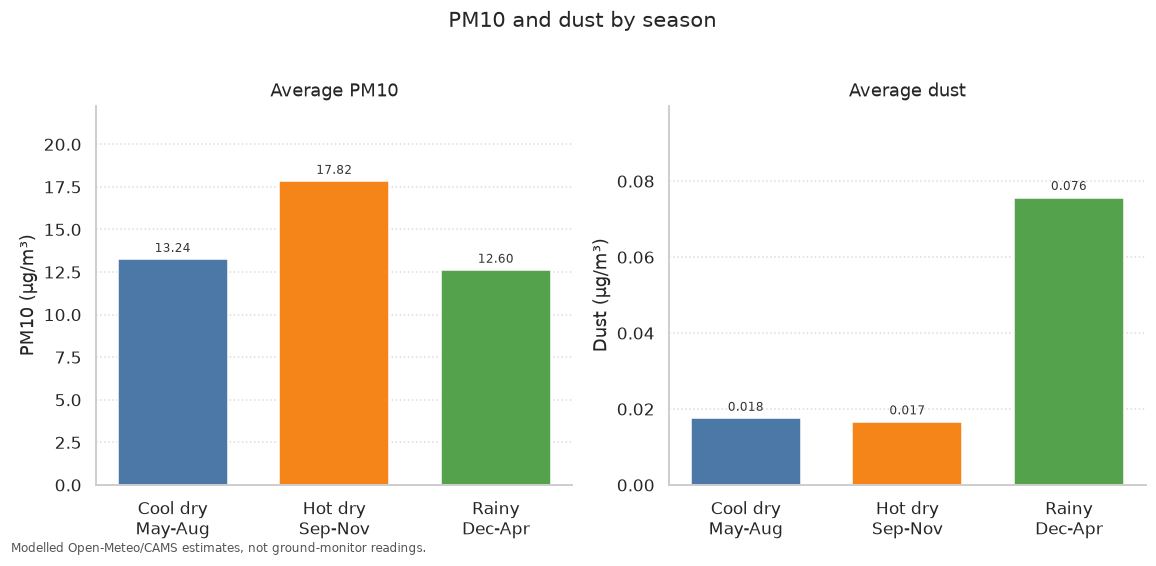

Finding: Mean PM10 is 15.43 µg/m³ in the dry season (May-Nov) and 12.60 µg/m³ in the rainy season, so PM10 is 22.4% higher in the dry season than in the rainy season. The hot dry season is the highest of the three at 17.82 µg/m³. Mean dust is 0.017 µg/m³ in the dry season and 0.076 µg/m³ in the rainy season. Mean dust is higher in the rainy season than in the dry season. The median dust is 0 in every season. Dust is above zero on 94 of 1,295 days (2022: 0, 2023: 3, 2024: 7, 2025: 67, 2026: 17).
On 2023-2025 only, mean PM10 is 13.59 µg/m³ in the dry season and 12.29 µg/m³ in the rainy season. Mean dust is 0.020 µg/m³ (dry) and 0.063 µg/m³ (rainy).


In [7]:
season_air = (
    daily.groupby("season", as_index=False)
    .agg(
        days=("pm10", "count"),
        average_pm10=("pm10", "mean"),
        median_pm10=("pm10", "median"),
        average_dust=("dust", "mean"),
        median_dust=("dust", "median"),
    )
)
season_air["season"] = pd.Categorical(
    season_air["season"], categories=SEASON_ORDER, ordered=True
)
season_air = season_air.sort_values("season")
dust_days = daily.loc[daily["dust"] > 0].groupby("season").size()
season_air["dust_days"] = (
    season_air["season"].astype(str).map(dust_days).fillna(0).astype(int)
)

dry = daily.loc[daily["is_dry_season"]]
rainy = daily.loc[~daily["is_dry_season"]]
dry_pm10 = dry["pm10"].mean()
rain_pm10 = rainy["pm10"].mean()
dry_dust = dry["dust"].mean()
rain_dust = rainy["dust"].mean()
pm10_pct = (dry_pm10 - rain_pm10) / rain_pm10 * 100

print("PM10 and dust by season. Concentrations are µg/m³.")
view = season_air.copy()
view["months"] = view["season"].astype(str).map(SEASON_MONTHS)
for column, places in (("average_pm10", 2), ("median_pm10", 2), ("average_dust", 3), ("median_dust", 3)):
    view[column] = view[column].round(places)
view = view.rename(columns={
    "season": "Season",
    "months": "Months",
    "days": "Days",
    "average_pm10": "Average PM10",
    "median_pm10": "Median PM10",
    "average_dust": "Average dust",
    "median_dust": "Median dust",
    "dust_days": "Days with dust > 0",
})
display(view[[
    "Season", "Months", "Days", "Average PM10", "Median PM10",
    "Average dust", "Median dust", "Days with dust > 0",
]])

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.9))
labels = [f"{season}\n{SEASON_MONTHS[str(season)]}" for season in season_air["season"]]
colors = [SEASON_COLORS[str(season)] for season in season_air["season"]]
positions = list(range(len(labels)))
axes[0].bar(positions, season_air["average_pm10"], color=colors, width=0.68)
axes[1].bar(positions, season_air["average_dust"], color=colors, width=0.68)
axes[0].set_ylim(0, season_air["average_pm10"].max() * 1.25)
axes[1].set_ylim(0, season_air["average_dust"].max() * 1.32)
label_bars(axes[0], "{:.2f}")
label_bars(axes[1], "{:.3f}")
axes[0].set_title("Average PM10")
axes[0].set_ylabel("PM10 (µg/m³)")
axes[1].set_title("Average dust")
axes[1].set_ylabel("Dust (µg/m³)")
for ax in axes:
    ax.set_xticks(positions)
    ax.set_xticklabels(labels)
    style_ax(ax)
fig.suptitle("PM10 and dust by season", fontsize=14, y=1.02)
add_source_note(fig)
save_chart(fig, "dust_pm10_by_season.png")

pm10_by_season = season_air.set_index(season_air["season"].astype(str))["average_pm10"]
dust_positive = int((daily["dust"] > 0).sum())
dust_counts = daily.assign(has_dust=daily["dust"] > 0).groupby("year")["has_dust"].sum().astype(int)
dust_year_bits = ", ".join(f"{int(year)}: {int(count)}" for year, count in dust_counts.items())
if pm10_pct >= 0:
    pm10_clause = f"{pm10_pct:.1f}% higher in the dry season than in the rainy season"
else:
    pm10_clause = f"{abs(pm10_pct):.1f}% higher in the rainy season than in the dry season"
if rain_dust > dry_dust:
    dust_clause = "Mean dust is higher in the rainy season than in the dry season."
elif dry_dust > rain_dust:
    dust_clause = "Mean dust is higher in the dry season than in the rainy season."
else:
    dust_clause = "Mean dust is the same in both seasons."
medians = season_air.set_index(season_air["season"].astype(str))["median_dust"]
if (medians == 0).all():
    median_clause = "The median dust is 0 in every season."
else:
    median_clause = "Median dust by season: " + ", ".join(
        f"{season} {value:.3f}" for season, value in medians.items()
    )

# Same comparison on complete years, as a check that 2022 is not driving the result.
full = daily.loc[daily["year"].isin([2023, 2024, 2025])]
full_dry_pm10 = full.loc[full["is_dry_season"], "pm10"].mean()
full_rain_pm10 = full.loc[~full["is_dry_season"], "pm10"].mean()
full_dry_dust = full.loc[full["is_dry_season"], "dust"].mean()
full_rain_dust = full.loc[~full["is_dry_season"], "dust"].mean()

print(
    f"Finding: Mean PM10 is {dry_pm10:.2f} µg/m³ in the dry season (May-Nov) and "
    f"{rain_pm10:.2f} µg/m³ in the rainy season, so PM10 is {pm10_clause}. "
    f"The hot dry season is the highest of the three at {pm10_by_season.loc['Hot dry']:.2f} µg/m³. "
    f"Mean dust is {dry_dust:.3f} µg/m³ in the dry season and {rain_dust:.3f} µg/m³ in the rainy season. "
    f"{dust_clause} {median_clause} "
    f"Dust is above zero on {dust_positive} of {len(daily):,} days ({dust_year_bits})."
)
print(
    f"On 2023-2025 only, mean PM10 is {full_dry_pm10:.2f} µg/m³ in the dry season and "
    f"{full_rain_pm10:.2f} µg/m³ in the rainy season. "
    f"Mean dust is {full_dry_dust:.3f} µg/m³ (dry) and {full_rain_dust:.3f} µg/m³ (rainy)."
)

## Question 5: How are the pollutants correlated?

Pearson correlation is used. A value near 1 means the two columns rise and fall together. A value near 0 means they do not. A negative value means one tends to be high when the other is low.

Aerosol optical depth (AOD) is a measure of haze through the whole air column, not a ground-level concentration. It is included because it moves with particle pollution. US AQI is left off the heatmap: the index is built from pollutant levels, so its link with PM2.5 is reported separately.

Pearson correlation, rounded to two decimals.


,PM2.5,PM10,Dust,AOD,CO,NO2,SO2,Ozone
PM2.5,1.00,0.97,0.09,0.64,0.54,0.54,0.52,0.43
PM10,0.97,1.00,0.02,0.59,0.57,0.54,0.43,0.40
Dust,0.09,0.02,1.00,0.12,-0.03,0.02,0.19,-0.03
AOD,0.64,0.59,0.12,1.00,0.07,0.04,0.09,0.45
CO,0.54,0.57,-0.03,0.07,1.00,0.93,0.48,-0.18
NO2,0.54,0.54,0.02,0.04,0.93,1.00,0.59,-0.23
SO2,0.52,0.43,0.19,0.09,0.48,0.59,1.00,-0.00
Ozone,0.43,0.40,-0.03,0.45,-0.18,-0.23,-0.00,1.00


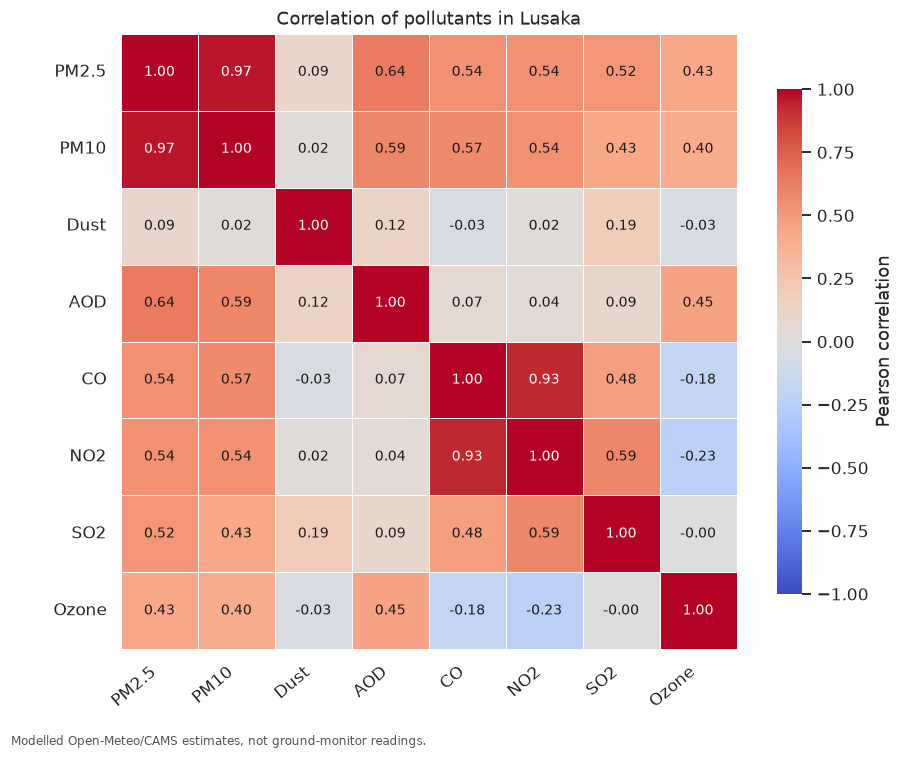

Finding: The strongest correlation is PM2.5 with PM10 (0.97). Next is CO with NO2 (0.93). The most negative pair is NO2 with Ozone (-0.23). Dust's strongest link is Dust with SO2 (0.19). US AQI and PM2.5 correlate at 0.92.


In [8]:
# Friendly names for the chart. The calculation still uses the file's column names.
pollutant_columns = {
    "pm2_5": "PM2.5",
    "pm10": "PM10",
    "dust": "Dust",
    "aerosol_optical_depth": "AOD",
    "carbon_monoxide": "CO",
    "nitrogen_dioxide": "NO2",
    "sulphur_dioxide": "SO2",
    "ozone": "Ozone",
}
corr = daily[list(pollutant_columns)].corr(method="pearson")
corr.index = [pollutant_columns[name] for name in corr.index]
corr.columns = [pollutant_columns[name] for name in corr.columns]

print("Pearson correlation, rounded to two decimals.")
display(corr.round(2))

fig, ax = plt.subplots(figsize=(8.4, 6.9))
ax.grid(False)
sns.heatmap(
    corr,
    ax=ax,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.82},
)
# White text on the darkest cells, so values near 1.00 stay readable.
for row_index, row_name in enumerate(corr.index):
    for col_index, col_name in enumerate(corr.columns):
        value = float(corr.loc[row_name, col_name])
        text_color = "white" if abs(value) >= 0.75 else "#1a1a1a"
        ax.text(
            col_index + 0.5,
            row_index + 0.5,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=9,
        )
ax.set_title("Correlation of pollutants in Lusaka")
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
add_source_note(fig)
save_chart(fig, "pollutant_correlation.png")

pairs = []
names = list(corr.columns)
for i, left in enumerate(names):
    for right in names[i + 1:]:
        value = float(corr.loc[left, right])
        pairs.append((left, right, value, abs(value)))
pairs = pd.DataFrame(pairs, columns=["left", "right", "correlation", "abs_corr"])
pairs = pairs.sort_values("abs_corr", ascending=False)
top = pairs.iloc[0]
second = pairs.iloc[1]
most_negative = pairs.loc[pairs["correlation"].idxmin()]
dust_pairs = pairs[(pairs["left"] == "Dust") | (pairs["right"] == "Dust")]
dust_top = dust_pairs.iloc[0]
aqi_pm = float(daily[["pm2_5", "us_aqi"]].dropna().corr().iloc[0, 1])

print(
    f"Finding: The strongest correlation is {top.left} with {top.right} ({top.correlation:.2f}). "
    f"Next is {second.left} with {second.right} ({second.correlation:.2f}). "
    f"The most negative pair is {most_negative.left} with {most_negative.right} "
    f"({most_negative.correlation:.2f}). "
    f"Dust's strongest link is {dust_top.left} with {dust_top.right} ({dust_top.correlation:.2f}). "
    f"US AQI and PM2.5 correlate at {aqi_pm:.2f}."
)

## Question 6: Is the air getting better or worse from 2023 to 2025?

Only full calendar years are compared. 2022 starts in August and 2026 ends in February, so those years mix a different set of seasons and are left out.

2024 is a full year too. It is in the table so that a change from 2023 to 2025 is not mistaken for a steady year-by-year trend. The chart itself is the comparison the question asks for: 2023 against 2025, month by month.

The 15 µg/m³ column uses the WHO 2021 24-hour PM2.5 guideline as a reference count. It is not a regulatory compliance test, and these are modelled values.

Full calendar years. PM concentrations are µg/m³. US AQI is the index in the file.


,Year,Days,Average PM2.5,Median PM2.5,Average PM10,Average US AQI,Days PM2.5 above 15,Sensitive-group days,Unhealthy days
0,2023,365,12.07,10.71,17.55,47.40,102,1,0
1,2024,366,8.23,6.43,11.63,36.15,41,0,0
2,2025,365,9.57,8.02,9.99,42.42,59,1,0


Month by month. Change is the 2025 average minus the 2023 average, in µg/m³.


,Month,PM2.5 2023,PM2.5 2025,Change
0,Jan,15.58,11.37,-4.22
1,Feb,20.63,13.73,-6.90
2,Mar,13.23,7.34,-5.88
3,Apr,11.65,6.02,-5.63
4,May,11.21,4.92,-6.28
5,Jun,14.50,7.23,-7.27
6,Jul,6.90,5.30,-1.60
7,Aug,9.76,11.00,1.24
8,Sep,16.06,17.57,1.51
9,Oct,12.90,13.28,0.38


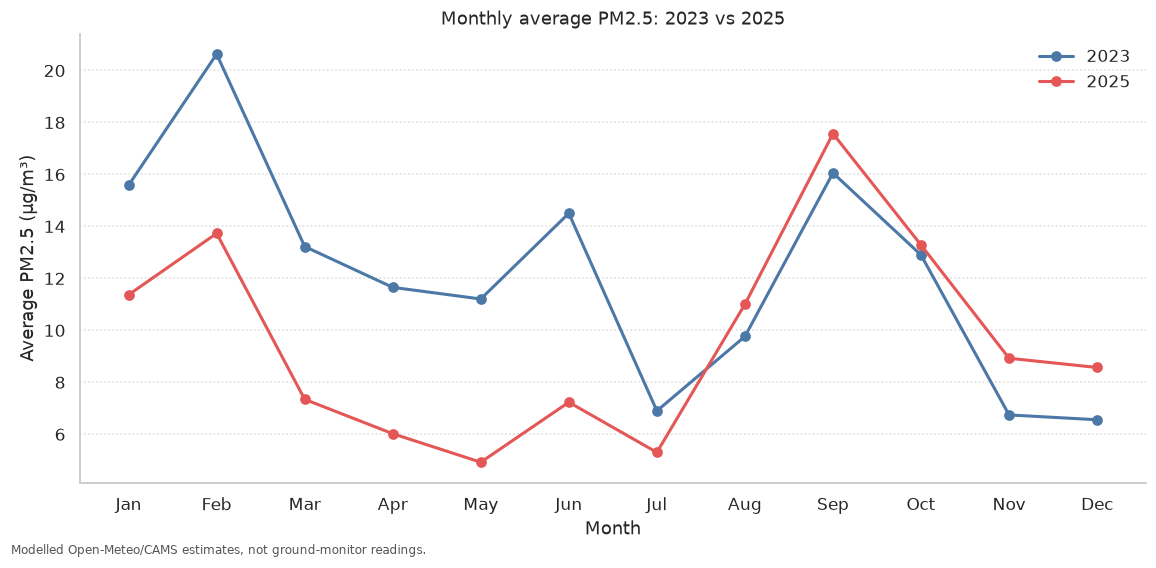

Finding: Mean PM2.5 moved from 12.07 µg/m³ in 2023 to 9.57 µg/m³ in 2025 (20.7% lower). Mean US AQI moved from 47.40 to 42.42 (10.5% lower). Mean PM10 moved from 17.55 to 9.99 µg/m³ (43.1% lower). Months that were lower in 2025: January, February, March, April, May, June, July (7 of 12). Months that were higher in 2025: August, September, October, November, December (5 of 12). 2024, the other full year, averaged 8.23 µg/m³ PM2.5. Days with PM2.5 above 15 µg/m³ fell from 102 in 2023 to 59 in 2025. Both annual means are above the WHO 2021 annual guideline of 5 µg/m³.


In [9]:
# WHO global air quality guidelines (2021): annual PM2.5 of 5 µg/m³, 24-hour PM2.5 of 15 µg/m³.
WHO_ANNUAL_PM25 = 5
WHO_DAILY_PM25 = 15

full_year_rows = []
for year in (2023, 2024, 2025):
    part = daily.loc[daily["year"] == year]
    aqi_part = with_aqi.loc[with_aqi["year"] == year]
    full_year_rows.append({
        "Year": year,
        "Days": len(part),
        "Average PM2.5": part["pm2_5"].mean(),
        "Median PM2.5": part["pm2_5"].median(),
        "Average PM10": part["pm10"].mean(),
        "Average US AQI": aqi_part["us_aqi"].mean(),
        "Days PM2.5 above 15": int((part["pm2_5"] > WHO_DAILY_PM25).sum()),
        "Sensitive-group days": int(((aqi_part["us_aqi"] >= 101) & (aqi_part["us_aqi"] <= 150)).sum()),
        "Unhealthy days": int((aqi_part["us_aqi"] > 150).sum()),
    })
full_year_table = pd.DataFrame(full_year_rows)

print("Full calendar years. PM concentrations are µg/m³. US AQI is the index in the file.")
show_years = full_year_table.copy()
for column in ("Average PM2.5", "Median PM2.5", "Average PM10", "Average US AQI"):
    show_years[column] = show_years[column].round(2)
display(show_years)

pm_2023 = daily.loc[daily["year"] == 2023].groupby("month")["pm2_5"].mean()
pm_2025 = daily.loc[daily["year"] == 2025].groupby("month")["pm2_5"].mean()
compare = pd.DataFrame({
    "Month": [MONTH_NAME[month] for month in range(1, 13)],
    "PM2.5 2023": [pm_2023.loc[month] for month in range(1, 13)],
    "PM2.5 2025": [pm_2025.loc[month] for month in range(1, 13)],
})
compare["Change"] = compare["PM2.5 2025"] - compare["PM2.5 2023"]
print("Month by month. Change is the 2025 average minus the 2023 average, in µg/m³.")
compare_view = compare.copy()
for column in ("PM2.5 2023", "PM2.5 2025", "Change"):
    compare_view[column] = compare_view[column].round(2)
display(compare_view)

fig, ax = plt.subplots(figsize=(10.6, 5.2))
ax.plot(compare["Month"], compare["PM2.5 2023"], marker="o", color="#4C78A8", linewidth=2, label="2023")
ax.plot(compare["Month"], compare["PM2.5 2025"], marker="o", color="#E45756", linewidth=2, label="2025")
ax.set_title("Monthly average PM2.5: 2023 vs 2025")
ax.set_ylabel("Average PM2.5 (µg/m³)")
ax.set_xlabel("Month")
ax.legend(loc="upper right")
style_ax(ax)
add_source_note(fig)
save_chart(fig, "pm25_2023_vs_2025.png")


def percent_lower(new, old) -> float:
    """How many percent lower `new` is than `old`. Negative means an increase."""
    return (old - new) / old * 100


row_2023 = full_year_table.loc[full_year_table["Year"] == 2023].iloc[0]
row_2024 = full_year_table.loc[full_year_table["Year"] == 2024].iloc[0]
row_2025 = full_year_table.loc[full_year_table["Year"] == 2025].iloc[0]
lower_months = [
    MONTH_NAME_FULL[month]
    for month in range(1, 13)
    if compare.loc[compare["Month"] == MONTH_NAME[month], "Change"].iloc[0] < 0
]
higher_months = [
    MONTH_NAME_FULL[month]
    for month in range(1, 13)
    if compare.loc[compare["Month"] == MONTH_NAME[month], "Change"].iloc[0] > 0
]

print(
    f"Finding: Mean PM2.5 moved from {row_2023['Average PM2.5']:.2f} µg/m³ in 2023 "
    f"to {row_2025['Average PM2.5']:.2f} µg/m³ in 2025 "
    f"({percent_lower(row_2025['Average PM2.5'], row_2023['Average PM2.5']):.1f}% lower). "
    f"Mean US AQI moved from {row_2023['Average US AQI']:.2f} to {row_2025['Average US AQI']:.2f} "
    f"({percent_lower(row_2025['Average US AQI'], row_2023['Average US AQI']):.1f}% lower). "
    f"Mean PM10 moved from {row_2023['Average PM10']:.2f} to {row_2025['Average PM10']:.2f} µg/m³ "
    f"({percent_lower(row_2025['Average PM10'], row_2023['Average PM10']):.1f}% lower). "
    f"Months that were lower in 2025: {', '.join(lower_months)} ({len(lower_months)} of 12). "
    f"Months that were higher in 2025: {', '.join(higher_months)} ({len(higher_months)} of 12). "
    f"2024, the other full year, averaged {row_2024['Average PM2.5']:.2f} µg/m³ PM2.5. "
    f"Days with PM2.5 above {WHO_DAILY_PM25:.0f} µg/m³ fell from "
    f"{int(row_2023['Days PM2.5 above 15'])} in 2023 to {int(row_2025['Days PM2.5 above 15'])} in 2025. "
    f"Both annual means are above the WHO 2021 annual guideline of {WHO_ANNUAL_PM25:.0f} µg/m³."
)

## What to keep in mind

- The series is a model product for one point in Lusaka (the coordinates in `city_info.csv`). A monitor in a busy junction, or one in a suburb, can read differently on the same day.
- The first three days of the file are blank, and 4 August 2022 has pollutants but no US AQI.
- 2022 and 2026 are partial. Month averages that use the whole file give extra weight to the months those years contain.
- Dust is zero on most days, and the non-zero dust days cluster late in the series. Treat the dust season result as a description of this CAMS field.
- A daily US AQI in the file can be an average of hourly index values. That is not always the same number as the AQI of the day's average concentration.
- Nothing here is medical advice or a statement about compliance with Zambian air-quality rules.

In [10]:
expected_charts = [
    "pm25_by_month.png",
    "pm25_by_season.png",
    "pm25_over_time.png",
    "pm25_by_month_full_years.png",
    "aqi_categories_by_year.png",
    "dust_pm10_by_season.png",
    "pollutant_correlation.png",
    "pm25_2023_vs_2025.png",
]
missing = [name for name in expected_charts if not (IMAGES / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing charts: {missing}")
print(f"Saved {len(expected_charts)} charts to {IMAGES.relative_to(ROOT)}/")
for name in expected_charts:
    print(f"  {name}")

Saved 8 charts to images/
  pm25_by_month.png
  pm25_by_season.png
  pm25_over_time.png
  pm25_by_month_full_years.png
  aqi_categories_by_year.png
  dust_pm10_by_season.png
  pollutant_correlation.png
  pm25_2023_vs_2025.png
